# Partie II : Apprentissage Supervisé sur Données Hétérogènes


**Objectif :** Comparer plusieurs algorithmes d'apprentissage supervisé sur le jeu de données **Credit Approval** (`credit.data`).
Ce jeu de données est plus complexe que le précédent car il est **hétérogène** (mélange de variables numériques et catégorielles) et contient des **valeurs manquantes**.

**Le Dataset :**
* **688 instances**
* **15 attributs** (6 numériques, 9 catégoriels)
* **Classe cible :** `+` (Crédit accordé) ou `-` (Crédit refusé)

**Trinome du TP :**
- CHARIF Taha Khalil : p2512972
- DJOUADI Hanane : p2512986
- MEZAOUROU Sidali : p2515000

### Importation des bibliothèques nécessaires

In [35]:
# Importation de NumPy pour le calcul numérique
import numpy as np
# Configuration des options d'affichage de NumPy
np.set_printoptions(threshold=10000, suppress=True)

# Importation de Pandas pour la manipulation de données
import pandas as pd

# Importation du module warnings pour gérer les avertissements
import warnings

# Importation de Matplotlib pour les visualisations
import matplotlib.pyplot as plt

# Importation de SimpleImputer pour l'imputation des valeurs manquantes
from sklearn.impute import SimpleImputer

# Ignorer tous les avertissements pour une sortie plus propre
warnings.filterwarnings('ignore')

# Importation des fonctions de division des données
from sklearn.model_selection import train_test_split

# Importation des classifieurs
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Importation des preprocesseurs
from sklearn.preprocessing import OneHotEncoder, StandardScaler


- pour importer les algorithmsf(+ les fonctions ou code du notebook.ipynb/partie I du projet) qu'on va par la suite les utiliser.

In [36]:
# Importation du module io pour gérer les flux d'entrée/sortie
import io

# Importation des context managers pour rediriger stdout et stderr
from contextlib import redirect_stdout, redirect_stderr

# Supprimer l'affichage pendant l'import
# Création d'un buffer StringIO pour capturer la sortie
f = io.StringIO()
# Redirection de la sortie standard et d'erreur vers le buffer
with redirect_stdout(f), redirect_stderr(f):
    # Importation des modules pour travailler avec des notebooks Jupyter
    import notebook      # Module de base pour les fonctionnalités de notebook

# Maintenant vous avez accès aux variables sans l'affichage
print("Import réussi !")

Import réussi !


## 1. Étude Préliminaire : Variables Numériques Uniquement

Dans cette première approche, nous simplifions le problème en ne considérant que les **6 variables continues (numériques)** et en supprimant les lignes contenant des données manquantes.

**Étapes :**
1.  **Chargement** du fichier `credit.data` (pas de header, séparateur espace).
2.  **Conversion** en tableau Numpy.
3.  **Séparation** des features ($X$) et de la cible ($y$).

In [37]:
# Chargement du fichier 'credit.data' dans un DataFrame pandas
# - header=None : pas d'en-tête dans le fichier
# - sep='\s+' : séparateur = un ou plusieurs espaces/tabulations
# - na_values='?' : interpréter '?' comme valeurs manquantes
df2 = pd.read_csv('credit.data', header=None, sep='\s+', na_values='?')

# Afficher les premières lignes pour inspection
print("Premières lignes du dataset")
print(df2.head())
print("\n")

# Vérifier le type de l'objet df2
print(f"Type du dataset : {type(df2)}") # On confirme qu'il s'agit bien d'un DataFrame pandas

Premières lignes du dataset
  0      1      2  3  4  5  6     7  8  9   10 11 12     13   14 15
0  b  30.83  0.000  u  g  w  v  1.25  t  t   1  f  g  202.0    0  +
1  a  58.67  4.460  u  g  q  h  3.04  t  t   6  f  g   43.0  560  +
2  a  24.50  0.500  u  g  q  h  1.50  t  f   0  f  g  280.0  824  +
3  b  27.83  1.540  u  g  w  v  3.75  t  t   5  t  g  100.0    3  +
4  b  20.17  5.625  u  g  w  v  1.71  t  f   0  f  s  120.0    0  +


Type du dataset : <class 'pandas.core.frame.DataFrame'>


### Transformation en numpy array

In [38]:
# 2. Transformation en numpy array
# Conversion du DataFrame pandas en tableau NumPy multidimensionnel
# .values extrait les données sous forme de tableau NumPy (sans les noms de colonnes)
df2_numpy = df2.values

# Affichage du tableau NumPy résultant
print(f" Transformation en numpy array\n {df2_numpy}")

# Vérification du type de l'objet pour confirmer la conversion
print(f"Type de data_array : {type(df2_numpy)}") # Confirmation de la transformation réussie en tableau NumPy

 Transformation en numpy array
 [['b' 30.83 0.0 ... 202.0 0 '+']
 ['a' 58.67 4.46 ... 43.0 560 '+']
 ['a' 24.5 0.5 ... 280.0 824 '+']
 ...
 ['a' 25.25 13.5 ... 200.0 1 '-']
 ['b' 17.92 0.205 ... 280.0 750 '-']
 ['b' 35.0 3.375 ... 0.0 0 '-']]
Type de data_array : <class 'numpy.ndarray'>


### Séparation des X et y

In [39]:
# Séparation des caractéristiques (X) et de la variable cible (y)
# X : Toutes les caractéristiques (features) du dataset
# [:, :-1] : Sélectionne toutes les lignes (:) et toutes les colonnes sauf la dernière (:-1)
X = df2_numpy[:, :-1]  # Toutes les colonnes sauf la dernière

# y : Variable cible (target) à prédire
# [:, -1] : Sélectionne toutes les lignes (:) et uniquement la dernière colonne (-1)
y = df2_numpy[:, -1]   # Dernière colonne (la variable cible)

### Détails du jeu de données

In [40]:
# Affichage des dimensions des caractéristiques X
print(f"Shape de X (caractéristiques): {X.shape}")

# Affichage des dimensions de la variable cible y
print(f"Shape de y (target): {y.shape}")

print("\nPremières lignes de X:")
# Affichage des 3 premières lignes de X pour visualiser les données
print(X[:3])

print("\nPremières valeurs de y:")
# Affichage des 3 premières valeurs de y pour visualiser la variable cible
print(y[:3])

Shape de X (caractéristiques): (688, 15)
Shape de y (target): (688,)

Premières lignes de X:
[['b' 30.83 0.0 'u' 'g' 'w' 'v' 1.25 't' 't' 1 'f' 'g' 202.0 0]
 ['a' 58.67 4.46 'u' 'g' 'q' 'h' 3.04 't' 't' 6 'f' 'g' 43.0 560]
 ['a' 24.5 0.5 'u' 'g' 'q' 'h' 1.5 't' 'f' 0 'f' 'g' 280.0 824]]

Premières valeurs de y:
['+' '+' '+']


### Nettoyage des Données

Nous isolons les colonnes numériques et traitons les valeurs manquantes représentées par le caractère `'?'`.
* Remplacement de `'?'` par `NaN`.
* Conversion des données en format `float`.
* **Suppression** pure et simple des individus ayant au moins une valeur manquante (perte d'information).

In [41]:
# Colonnes avec des valeurs numériques : indices 1, 2, 7, 10, 13, 14
# Ces indices correspondent aux colonnes numériques dans le dataset original
numerical_indices = [1, 2, 7, 10, 13, 14]

# Création du sous-ensemble avec seulement les variables numériques
# Sélection des colonnes spécifiées par numerical_indices dans X
X_numerical = X[:, numerical_indices]

In [42]:
# Remplacer '?' par NaN (Not a Number) dans le tableau numérique
# np.where() remplace toutes les occurrences de '?' par np.nan
X_numerical = np.where(X_numerical == '?', np.nan, X_numerical)

# Conversion des données en type float
# astype(float) convertit toutes les valeurs en nombres flottants
# Note : NaN est déjà compatible avec le type float
X_numerical = X_numerical.astype(float)

In [43]:
# Affichage de la forme du sous-ensemble numérique
print(f"Shape du sous-ensemble numérique: {X_numerical.shape}")

# Affichage du type de données du tableau NumPy
print(f"Type: {X_numerical.dtype}")

print("\nPremières lignes:")
# Affichage des 5 premières lignes pour vérifier la conversion
print(X_numerical[:5])

Shape du sous-ensemble numérique: (688, 6)
Type: float64

Premières lignes:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]


In [44]:
# Supprimer les individus avec des valeurs manquantes (nan)
# Création d'un masque booléen : True pour les lignes sans NaN, False pour les lignes avec NaN
# np.isnan(X_numerical) : identifie les valeurs NaN dans X_numerical
# np.any(..., axis=1) : vérifie s'il y a au moins un NaN par ligne
# ~ : opérateur NOT (inverse les valeurs booléennes)
mask = ~np.any(np.isnan(X_numerical), axis=1)

# Application du masque pour garder seulement les lignes sans NaN
X_clean = X_numerical[mask]  # Caractéristiques nettoyées
y_clean = y[mask]            # Variable cible correspondante

In [45]:
print(f"Shape après suppression des NaN - X_clean: {X_clean.shape}")
print(f"Shape après suppression des NaN - y_clean: {y_clean.shape}")

Shape après suppression des NaN - X_clean: (666, 6)
Shape après suppression des NaN - y_clean: (666,)


In [46]:
# Analyser les propriétés
print(f"\nTaille de l'échantillon: {X_clean.shape[0]} instances")
print(f"Nombre de caractéristiques numériques: {X_clean.shape[1]}")


Taille de l'échantillon: 666 instances
Nombre de caractéristiques numériques: 6


### Analyse et Binarisation de la Cible

La variable cible est nominale (`+` / `-`). Pour l'apprentissage, nous devons la binariser :
* `+` devient **1**
* `-` devient **0**

Nous vérifions également la distribution des classes pour voir si le jeu de données est équilibré.

In [47]:
# Compter les exemples positifs et négatifs
# np.unique() avec return_counts=True retourne les valeurs uniques et leurs occurrences
unique, counts = np.unique(y_clean, return_counts=True)

# Affichage de la distribution des classes sous forme de dictionnaire
# zip() combine les deux tableaux unique et counts
# dict() crée un dictionnaire à partir des paires clé-valeur
print(f"\nDistribution des classes: {dict(zip(unique, counts))}")


Distribution des classes: {'+': np.int64(299), '-': np.int64(367)}


In [48]:
# Binariser la target (+ en 1 et - en 0)
# np.where() fonctionne comme une opération conditionnelle vectorisée
# Pour chaque élément dans y_clean :
#   - Si égal à '+', remplace par 1
#   - Sinon, remplace par 0
y_binary = np.where(y_clean == '+', 1, 0)

print(f"\nAprès binarisation {dict(zip(['0 (-)', '1 (+)'], np.bincount(y_binary)))}")


Après binarisation {'0 (-)': np.int64(367), '1 (+)': np.int64(299)}


In [49]:
# Affichage des 3 premières lignes des caractéristiques nettoyées
print(X_clean[:3])

# Affichage des 3 premières valeurs de la variable cible originale
print(y_clean[:3])

# Affichage des 3 premières valeurs de la variable cible binarisée
print(y_binary[:3])

[[ 30.83   0.     1.25   1.   202.     0.  ]
 [ 58.67   4.46   3.04   6.    43.   560.  ]
 [ 24.5    0.5    1.5    0.   280.   824.  ]]
['+' '+' '+']
[1 1 1]


In [50]:
# Affichage de la distribution de la variable cible binarisée
print("Target binarisée:")

# Compter le nombre d'occurrences de la classe 0 (négative, '-')
print("Classe 0 (-):", np.sum(y_binary == 0))

# Compter le nombre d'occurrences de la classe 1 (positive, '+')
print("Classe 1 (+):", np.sum(y_binary == 1))

Target binarisée:
Classe 0 (-): 367
Classe 1 (+): 299


### Apprentissage et Évaluation (Données Brutes)

Nous divisons les données en ensemble d'apprentissage et de test (70% / 30%) de manière stratifiée.
Nous appliquons ensuite trois classifieurs de référence sur ces données numériques brutes :
* **CART** (Arbre de décision)
* **KNN** ($k=5$)
* **MLP** (Réseau de neurones)

Les performances sont évaluées via la matrice de confusion et la courbe ROC.

In [51]:
# Division train-test pour utiliser la fonction run_classifiers_train_test du notebook

# Division stratifiée des données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,      # Caractéristiques nettoyées
    y_binary,     # Variable cible binarisée
    test_size=0.3,           # 30% des données pour le test
    random_state=42,         # Graine aléatoire pour reproductibilité
    stratify=y_binary        # Stratification pour conserver la distribution des classes
)

In [52]:
# Affichage des dimensions après division train-test
print(f"\nDivision train-test:")

# Dimensions de l'ensemble d'entraînement
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")

# Dimensions de l'ensemble de test
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Division train-test:
X_train: (466, 6), y_train: (466,)
X_test: (200, 6), y_test: (200,)


### Algorithmes utilisés

Algorithmes: ['CART', 'KNN-5', 'MLP']
Début de l'apprentissage...
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.6850
Precision:   0.6901
Recall:      0.5444
Score final: 0.6147 (Accuracy + Recall)/2
AUC:         0.7284

 MLP
------------------------------
Accuracy:    0.7200
Precision:   0.7179
Recall:      0.6222
Score final: 0.6711 (Accuracy + Recall)/2
AUC:         0.7460

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6147
MLP        : 0.6711

 MEILLEUR MODÈLE: MLP avec un score de 0.6711

VISUALISATIONS

Courbes ROC :


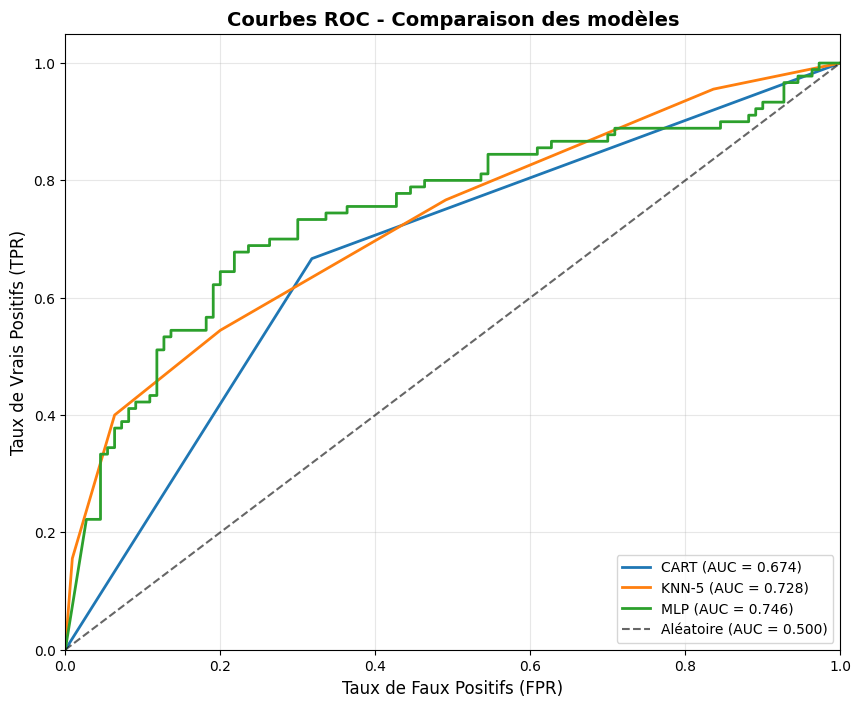


Matrices de confusion :


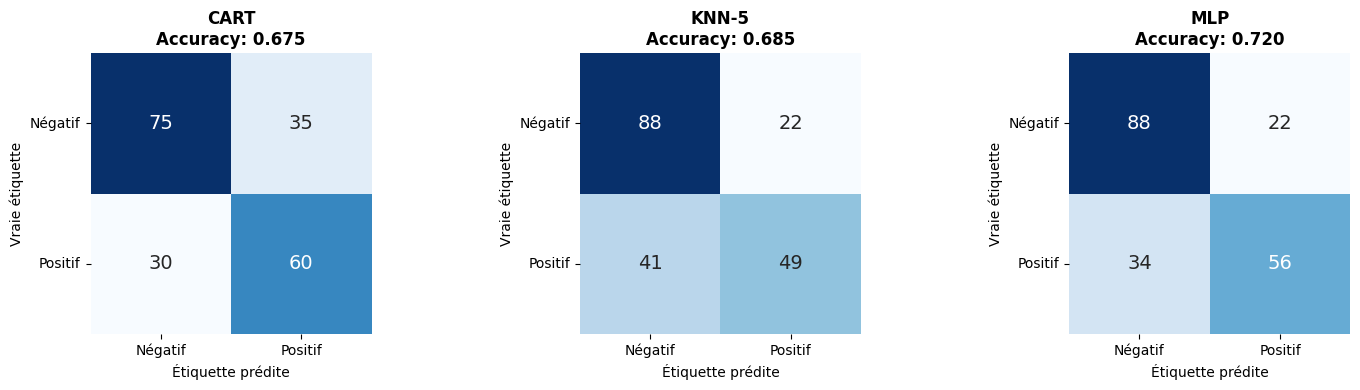


 MEILLEUR MODÈLE SÉLECTIONNÉ: MLP


In [53]:
# Affichage des algorithmes disponibles dans le notebook
print("Algorithmes:", list(notebook.algorithms.keys()))

# Début du processus d'apprentissage
print("Début de l'apprentissage...")

# Appel de la fonction principale d'entraînement et d'évaluation
best_model, best_model_name, all_results = notebook.run_classifiers_train_test(
    X_train, X_test, y_train, y_test
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC - comparaison graphique des performances
print("\nCourbes ROC :")
notebook.plot_roc_curves(all_results)

# Matrices de confusion - analyse des erreurs de classification
print("\nMatrices de confusion :")
notebook.plot_confusion_matrices(all_results)

# Affichage du meilleur modèle sélectionné
print(f"\n MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

### Impact de la Normalisation

Certains algorithmes, comme le KNN et le MLP, sont sensibles aux échelles des variables.
Nous utilisons le **StandardScaler** pour centrer et réduire les données (moyenne = 0, écart-type = 1) avant de relancer l'apprentissage.

In [54]:
# Normalisation des données
print("NORMALISATION DES DONNÉES")

# Appel de la fonction de normalisation avec StandardScaler
X_train_std, X_test_std, scaler_std = notebook.normalize_data(X_train, X_test, method='standard')

print("Données normalisées avec StandardScaler")
print(f"Shape X_train normalisé: {X_train_std.shape}")
print(f"Shape X_test normalisé: {X_test_std.shape}")

# Statistiques avant/après normalisation
print("\nCOMPARAISON AVANT/APRÈS NORMALISATION")

# Moyennes des 5 premières caractéristiques avant et après normalisation
print("Moyennes (avant normalisation):", np.mean(X_train, axis=0)[:5])  # 5 premières features
print("Moyennes (après normalisation):", np.mean(X_train_std, axis=0)[:5])

# Écart-types des 5 premières caractéristiques avant et après normalisation
print("\nÉcart-types (avant normalisation):", np.std(X_train, axis=0)[:5])
print("Écart-types (après normalisation):", np.std(X_train_std, axis=0)[:5])

NORMALISATION DES DONNÉES
Données normalisées avec StandardScaler
Shape X_train normalisé: (466, 6)
Shape X_test normalisé: (200, 6)

COMPARAISON AVANT/APRÈS NORMALISATION
Moyennes (avant normalisation): [ 31.96843348   4.84853004   2.18312232   2.57725322 183.62446352]
Moyennes (après normalisation): [ 0.  0.  0. -0. -0.]

Écart-types (avant normalisation): [ 11.93751385   5.05632146   3.36891565   5.35754229 172.57950386]
Écart-types (après normalisation): [1. 1. 1. 1. 1.]


In [55]:
# Exécution des modèles sur données normalisées
print("=" * 70)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)")
print("=" * 70)

# Appel de la fonction d'entraînement avec les données normalisées
best_model_std, best_model_name_std, results_std = notebook.run_classifiers_train_test(
    X_train_std, X_test_std, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.7250
Precision:   0.7465
Recall:      0.5889
Score final: 0.6569 (Accuracy + Recall)/2
AUC:         0.7903

 MLP
------------------------------
Accuracy:    0.8000
Precision:   0.7778
Recall:      0.7778
Score final: 0.7889 (Accuracy + Recall)/2
AUC:         0.8355

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6569
MLP        : 0.7889

 MEILLEUR MODÈLE: MLP avec un score de 0.7889


## 2. Approche Complète : Données Hétérogènes et Imputation

La suppression des lignes incomplètes a réduit la taille de notre échantillon. Nous allons maintenant utiliser **toutes les variables** (catégorielles et numériques) et conserver tous les individus en **imputant les valeurs manquantes**.

**Stratégie :**
* Variables **Numériques** : Imputation par la **moyenne**.
* Variables **Catégorielles** : Imputation par la **valeur la plus fréquente** (mode).

In [56]:
# Définition des indices des colonnes numériques dans le dataset original
col_num = [1, 2, 7, 10, 13, 14]  # Indices des colonnes contenant des données numériques

# Définition des indices des colonnes catégorielles dans le dataset original
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]  # Indices des colonnes contenant des données catégorielles

# Affichage des indices des colonnes
print("Colonnes numériques:", col_num)
print("Colonnes catégorielles:", col_cat)

Colonnes numériques: [1, 2, 7, 10, 13, 14]
Colonnes catégorielles: [0, 3, 4, 5, 6, 8, 9, 11, 12]


### Traitement des Variables Catégorielles

Les algorithmes classiques ne gèrent pas les chaînes de caractères. Nous procédons en deux étapes :
1.  **Encodage numérique simple** pour pouvoir utiliser les outils d'imputation.
2.  **Imputation** des valeurs manquantes.

In [57]:
# Copier les colonnes catégorielles de X dans un nouveau tableau
X_cat = np.copy(X[:, col_cat])

# Affichage des dimensions des données catégorielles
print("Shape des données catégorielles:", X_cat.shape)

print("\nExemple de données catégorielles avant transformation:")
# Affichage des 5 premières lignes des données catégorielles brutes
print(X_cat[:5])

# Transformer les valeurs catégorielles en valeurs numériques
# Création d'un tableau vide pour stocker les données encodées
X_cat_encoded = np.empty(X_cat.shape, dtype=int)

# Encodage de chaque colonne catégorielle
for col_id in range(len(col_cat)):
    # Conversion en string pour éviter les problèmes de type
    col_values = X_cat[:, col_id].astype(str)
    # np.unique avec return_inverse=True donne les valeurs uniques et leurs indices
    unique_val, val_idx = np.unique(col_values, return_inverse=True)
    # Stockage des indices encodés dans le tableau
    X_cat_encoded[:, col_id] = val_idx
    print(f"\nColonne {col_cat[col_id]}: {len(unique_val)} modalités uniques")

# Remplacement du tableau original par le tableau encodé
X_cat = X_cat_encoded

print("\nDonnées catégorielles après transformation:")
# Affichage des 5 premières lignes des données catégorielles encodées
print(X_cat[:5])

Shape des données catégorielles: (688, 9)

Exemple de données catégorielles avant transformation:
[['b' 'u' 'g' 'w' 'v' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 'f' 'f' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 't' 't' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 'f' 'f' 's']]

Colonne 0: 3 modalités uniques

Colonne 3: 4 modalités uniques

Colonne 4: 4 modalités uniques

Colonne 5: 15 modalités uniques

Colonne 6: 10 modalités uniques

Colonne 8: 2 modalités uniques

Colonne 9: 2 modalités uniques

Colonne 11: 2 modalités uniques

Colonne 12: 3 modalités uniques

Données catégorielles après transformation:
[[ 1  2  0 13  8  1  1  0  0]
 [ 0  2  0 11  3  1  1  0  0]
 [ 0  2  0 11  3  1  0  0  0]
 [ 1  2  0 13  8  1  1  1  0]
 [ 1  2  0 13  8  1  0  0  2]]


In [58]:
# Remplacer '0' qui correspond à '?' par la valeur la plus fréquente
# Note : après l'encodage avec np.unique, '?' devient souvent la valeur 0
# Conversion en float pour la compatibilité avec SimpleImputer
X_cat = X_cat.astype(float)

# Imputation avec la stratégie 'most_frequent' (valeur la plus fréquente)
# missing_values=0 : considère 0 comme valeur manquante à imputer
imp_cat = SimpleImputer(missing_values=0, strategy='most_frequent')
X_cat = imp_cat.fit_transform(X_cat)

# Vérification qu'il n'y a plus de valeurs manquantes après imputation
print("Valeurs manquantes dans X_cat après imputation:", np.sum(np.isnan(X_cat)))

print("\nDonnées catégorielles après imputation:")
# Affichage des 5 premières lignes après imputation
print(X_cat[:5])

Valeurs manquantes dans X_cat après imputation: 0

Données catégorielles après imputation:
[[ 1.  2.  3. 13.  8.  1.  1.  1.  2.]
 [ 1.  2.  3. 11.  3.  1.  1.  1.  2.]
 [ 1.  2.  3. 11.  3.  1.  1.  1.  2.]
 [ 1.  2.  3. 13.  8.  1.  1.  1.  2.]
 [ 1.  2.  3. 13.  8.  1.  1.  1.  2.]]


In [59]:
# Copier les colonnes numériques de X dans un nouveau tableau
X_num = np.copy(X[:, col_num])

# Affichage des dimensions des données numériques
print("Shape des données numériques:", X_num.shape)

print("\nExemple de données numériques avant transformation:")
# Affichage des 5 premières lignes des données numériques brutes
print(X_num[:5])

# Remplacer toutes les occurrences de '?' par NaN (Not a Number)
X_num[X_num == '?'] = np.nan

# Conversion en type float pour permettre les opérations numériques
X_num = X_num.astype(float)

print("\nNombre de valeurs manquantes par colonne numérique:")
# Parcours de chaque colonne numérique pour compter les NaN
for i in range(X_num.shape[1]):
    count_nan = np.sum(np.isnan(X_num[:, i]))
    print(f"Colonne {col_num[i]}: {count_nan} NaN")

Shape des données numériques: (688, 6)

Exemple de données numériques avant transformation:
[[30.83 0.0 1.25 1 202.0 0]
 [58.67 4.46 3.04 6 43.0 560]
 [24.5 0.5 1.5 0 280.0 824]
 [27.83 1.54 3.75 5 100.0 3]
 [20.17 5.625 1.71 0 120.0 0]]

Nombre de valeurs manquantes par colonne numérique:
Colonne 1: 12 NaN
Colonne 2: 0 NaN
Colonne 7: 0 NaN
Colonne 10: 0 NaN
Colonne 13: 11 NaN
Colonne 14: 0 NaN


In [60]:
# Imputer les valeurs manquantes avec la moyenne de chaque colonne
# missing_values=np.nan : indique que NaN sont les valeurs manquantes à remplacer
# strategy='mean' : utilise la moyenne de chaque colonne pour l'imputation
imp_num = SimpleImputer(missing_values=np.nan, strategy='mean')
X_num = imp_num.fit_transform(X_num)

# Vérification qu'il n'y a plus de valeurs manquantes après imputation
print("Valeurs manquantes dans X_num après imputation:", np.sum(np.isnan(X_num)))

print("\nDonnées numériques après imputation:")
# Affichage des 5 premières lignes après imputation
print(X_num[:5])

print("\nStatistiques des variables numériques:")
# Calcul et affichage des moyennes de chaque colonne numérique
print("Moyennes:", np.mean(X_num, axis=0))
# Calcul et affichage des écarts-types de chaque colonne numérique
print("Écarts-types:", np.std(X_num, axis=0))

Valeurs manquantes dans X_num après imputation: 0

Données numériques après imputation:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]

Statistiques des variables numériques:
Moyennes: [  31.5189497     4.76856105    2.22659884    2.39825581  184.01477105
 1019.47093023]
Écarts-types: [  11.760483      4.97787639    3.34786991    4.86367616  172.28434385
 5213.71865786]


### Encodage One-Hot

Pour éviter d'introduire une relation d'ordre inexistante entre les catégories, nous utilisons le **One-Hot Encoding**.
Chaque variable catégorielle à $m$ modalités est transformée en $m$ variables binaires.

In [61]:
# Encoder les variables catégorielles en variables binaires (one-hot encoding)
# sparse_output=False : retourne un tableau dense (non sparse) pour faciliter l'affichage
encoder = OneHotEncoder(sparse_output=False)

# Transformation des données catégorielles en variables binaires
X_cat_bin = encoder.fit_transform(X_cat)

# Affichage des informations sur les données transformées
print("Shape après One-Hot Encoding:", X_cat_bin.shape)
print("Nombre de features catégorielles binaires créées:", X_cat_bin.shape[1])

print("\nExemple de données après One-Hot Encoding:")
# Affichage des 5 premières lignes et 10 premières colonnes pour visualisation
print(X_cat_bin[:5, :10])  # Afficher les 10 premières colonnes

Shape après One-Hot Encoding: (688, 36)
Nombre de features catégorielles binaires créées: 36

Exemple de données après One-Hot Encoding:
[[1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]]


### Standardisation des Variables Numériques
Nous appliquons à nouveau une standardisation sur les variables numériques après l'imputation.

In [62]:
# Normaliser les variables continues avec StandardScaler
# StandardScaler centre et réduit les données (moyenne=0, écart-type=1)
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

print("Données numériques après normalisation:")
# Vérification que la normalisation fonctionne bien (moyennes proches de 0)
print("Moyennes:", np.mean(X_num_scaled, axis=0))
# Vérification que les écarts-types sont proches de 1
print("Écarts-types:", np.std(X_num_scaled, axis=0))

print("\nExemple de données normalisées:")
# Affichage des 5 premières lignes des données normalisées
print(X_num_scaled[:5])

Données numériques après normalisation:
Moyennes: [-0.  0.  0. -0.  0.  0.]
Écarts-types: [1. 1. 1. 1. 1. 1.]

Exemple de données normalisées:
[[-0.05858175 -0.95795088 -0.29170752 -0.2874895   0.10439271 -0.19553624]
 [ 2.30866796 -0.06198648  0.2429608   0.74053947 -0.81850021 -0.0881273 ]
 [-0.59682495 -0.85750644 -0.21703318 -0.49309529  0.55713263 -0.03749165]
 [-0.31367332 -0.648582    0.45503595  0.53493368 -0.4876518  -0.19496083]
 [-0.96500711  0.17204906 -0.15430672 -0.49309529 -0.37156464 -0.19553624]]


### Construction du Jeu de Données Final

Nous assemblons le jeu de données complet pour l'apprentissage final :
1.  Variables numériques **normalisées**.
2.  Variables catégorielles **encodées** (binaires).

In [63]:
# Concaténer les données catégorielles encodées et les données numériques normalisées
# axis=1 : concaténation par colonnes (ajout de nouvelles caractéristiques)
X_final = np.concatenate([X_cat_bin, X_num_scaled], axis=1)

print("Shape du jeu de données final:", X_final.shape)
print("Nombre total de features:", X_final.shape[1])
print("  - Features catégorielles (binaires):", X_cat_bin.shape[1])
print("  - Features numériques (normalisées):", X_num_scaled.shape[1])

# Vérifier les formes des tableaux
print("X_final shape:", X_final.shape)
print("y_binary shape:", y_binary.shape)

# Vérifier les types des tableaux
print("\nType de X_final:", type(X_final))
print("Type de y_binary:", type(y_binary))

# Comme X_final est un tableau NumPy, on doit simplement tronquer au minimum
# Calcul de la longueur minimale entre X_final et y_binary
min_length = min(X_final.shape[0], y_binary.shape[0])
print(f"\nLongueur minimale: {min_length}")
print(f"Échantillons à supprimer de X_final: {X_final.shape[0] - min_length}")

# Tronquer X_final pour correspondre à y_binary
X_final_trimmed = X_final[:min_length]  # Garde les min_length premières lignes
y_binary_trimmed = y_binary[:min_length]  # Garde les min_length premières lignes

print("\nAprès ajustement:")
print("X_final_trimmed shape:", X_final_trimmed.shape)
print("y_binary_trimmed shape:", y_binary_trimmed.shape)

# Vérifier la distribution des classes après troncature
print("\nDistribution des classes:")
unique, counts = np.unique(y_binary_trimmed, return_counts=True)
for u, c in zip(unique, counts):
    print(f"Classe {int(u)}: {c}")



Shape du jeu de données final: (688, 42)
Nombre total de features: 42
  - Features catégorielles (binaires): 36
  - Features numériques (normalisées): 6
X_final shape: (688, 42)
y_binary shape: (666,)

Type de X_final: <class 'numpy.ndarray'>
Type de y_binary: <class 'numpy.ndarray'>

Longueur minimale: 666
Échantillons à supprimer de X_final: 22

Après ajustement:
X_final_trimmed shape: (666, 42)
y_binary_trimmed shape: (666,)

Distribution des classes:
Classe 0: 367
Classe 1: 299


### Évaluation Finale

Nous entraînons nos modèles sur ce nouveau jeu de données enrichi.
L'objectif est de vérifier si l'ajout des variables catégorielles et la conservation de tous les individus (via imputation) améliorent les performances (Accuracy, AUC) par rapport à l'approche naïve sur les variables numériques seules.

In [64]:


# Division des données en ensembles d'entraînement et de test
X_train, X_test, Y_train, Y_test = train_test_split(
    X_final_trimmed,  # Caractéristiques finales
    y_binary_trimmed, # Variable cible binarisée
    test_size=0.5,    # 50% pour le test
    random_state=1    # Graine aléatoire pour reproductibilité
)

print("\nSéparation train/test:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# Distribution des classes dans les ensembles d'entraînement et de test
print("Y_train - Classe 0:", np.sum(Y_train == 0), "| Classe 1:", np.sum(Y_train == 1))
print("Y_test - Classe 0:", np.sum(Y_test == 0), "| Classe 1:", np.sum(Y_test == 1))


Séparation train/test:
X_train shape: (333, 42)
X_test shape: (333, 42)
Y_train - Classe 0: 179 | Classe 1: 154
Y_test - Classe 0: 188 | Classe 1: 145


=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6126
Precision:   0.5588
Recall:      0.5241
Score final: 0.5684 (Accuracy + Recall)/2
AUC:         0.6025

 KNN-5
------------------------------
Accuracy:    0.7237
Precision:   0.7054
Recall:      0.6276
Score final: 0.6757 (Accuracy + Recall)/2
AUC:         0.7543

 MLP
------------------------------
Accuracy:    0.6517
Precision:   0.6028
Recall:      0.5862
Score final: 0.6189 (Accuracy + Recall)/2
AUC:         0.7258

COMPARAISON DES MODÈLES
CART       : 0.5684
KNN-5      : 0.6757
MLP        : 0.6189

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.6757

VISUALISATIONS

Courbes ROC :


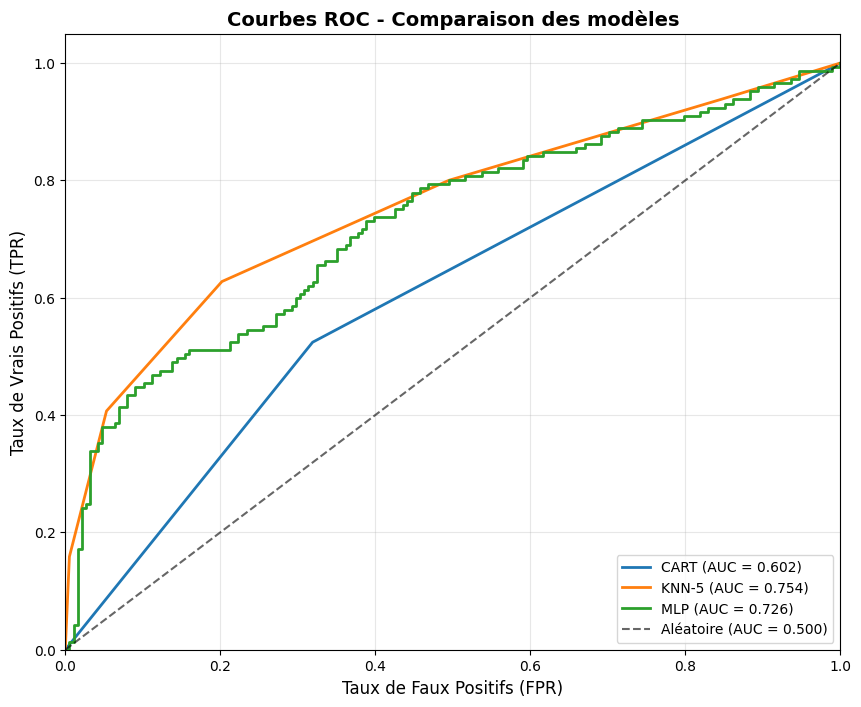


Matrices de confusion :


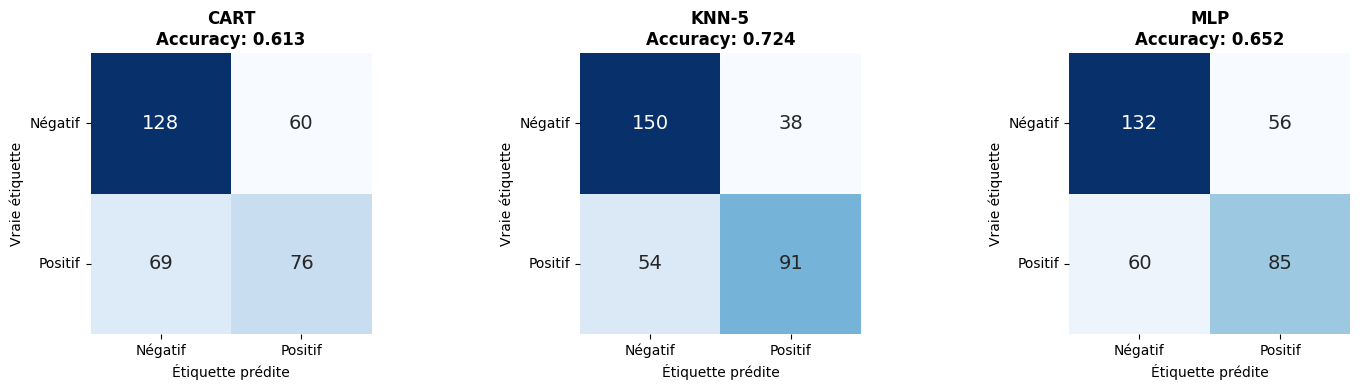


🏆 MEILLEUR MODÈLE SÉLECTIONNÉ: KNN-5


In [65]:
# Définition du dictionnaire d'algorithmes avec leurs configurations
algorithms = {
    'CART': DecisionTreeClassifier(random_state=1),  # Arbre de décision
    'KNN-5': KNeighborsClassifier(n_neighbors=5),    # KNN avec k=5
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=1000)  # Perceptron multicouche
}

# Appel de la fonction d'entraînement et d'évaluation
# La fonction retourne (best_model, best_name, results)
best_model, best_model_name, all_results_dict = notebook.run_classifiers_train_test(
    X_train, X_test, Y_train, Y_test  # Utilisation de Y_train et Y_test (avec majuscules)
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC - comparaison graphique des performances
print("\nCourbes ROC :")
notebook.plot_roc_curves(all_results_dict)

# Matrices de confusion - analyse des erreurs
print("\nMatrices de confusion :")
notebook.plot_confusion_matrices(all_results_dict)

# Affichage du meilleur modèle identifié
print(f"\n🏆 MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")